# Figure 5e–j · Figure S8 — short test

Seven controller architectures and Large maze. Updated flat-ground/S7 results use [05_ant_flat.ipynb](05_ant_flat.ipynb). The prerequisite policies and teacher-label stages run automatically.

The saved tables and figures below come from a real short test and can be viewed directly on GitHub. To regenerate them, use the **Python (FlyControl)** kernel; see [setup and notebook index](README.md). Run cells from top to bottom. This notebook executes the same six stages as the command-line workflow, with reduced budgets and one training seed. It keeps every configured method. **These are software checks, not paper results.**

First execution downloads versioned public inputs. Neural assays and multi-stage maze prerequisites can still take substantial time; “short” refers to the training budget, not a seconds-long demonstration. Generated checkpoints, data and figures stay under `runs/`.

Choose a fresh `RUN_DIR` after code/configuration changes or for an independent restart. A completed run can be inspected with the “Inspect the smoke outputs” cell without retraining.

## Settings

Launch Jupyter from the repository root or `notebooks/`. Select the installed FlyControl kernel before running.

`DEVICE` defaults to CPU. To use a GPU, set it to an available device (for example `cuda:0`) or launch Jupyter with `FLYCONTROL_NOTEBOOK_DEVICE=cuda:0`. The saved execution records the device actually used.

In [1]:
from pathlib import Path
import sys
import os

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
    and (path / "src/flycontrol").is_dir()
)
sys.path.insert(0, str(ROOT / "notebooks"))
from notebook_utils import run_stage, show_outputs

CONFIG = 'maze'
RUN_DIR = ROOT / "runs/notebooks/maze-capacity-regression-v2"
DEVICE = os.environ.get("FLYCONTROL_NOTEBOOK_DEVICE", "cpu")
WORKERS = 1
print(f"SMOKE TEST: {CONFIG} | {DEVICE} | {RUN_DIR.relative_to(ROOT)}")


SMOKE TEST: maze | cuda:1 | runs/notebooks/maze-capacity-regression-v2


## 1. Prepare

Download and checksum-verify public inputs, then resolve the reduced configuration. This cell always sets `--smoke`; all configured methods and the first training seed are retained.

In [2]:
run_stage("prepare", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: prepare** · 1.0 seconds · smoke test

Full execution log: `logs/notebook-prepare.log` within the run directory.

## 2. Train

Train fresh policies using the reduced budgets. This includes any prerequisites required by the selected experiment.

In [3]:
run_stage("train", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: train** · 467.8 seconds · smoke test

Full execution log: `logs/notebook-train.log` within the run directory.

## 3. Evaluate

Run the configured smoke evaluations in the real simulator, recording failures as well as successful episodes.

In [4]:
run_stage("evaluate", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: evaluate** · 189.0 seconds · smoke test

Full execution log: `logs/notebook-evaluate.log` within the run directory.

## 4. Probe

Run the configured neural assays. Experiments without a neural assay record that explicitly. Short-trained policies can fail the required histories; read the recorded exclusions.

In [5]:
run_stage("probe", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: probe** · 0.0 seconds · smoke test

Full execution log: `logs/notebook-probe.log` within the run directory.

## 5. Analyze

Aggregate the generated numerical records. Smoke outputs do not support the manuscript’s statistical conclusions.

In [6]:
run_stage("analyze", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: analyze** · 1.4 seconds · smoke test

Full execution log: `logs/notebook-analyze.log` within the run directory.

## 6. Plot

Create diagnostic panels, numerical sources and editable PDF/SVG figures from this run.

In [7]:
run_stage("plot", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: plot** · 35.2 seconds · smoke test

Full execution log: `logs/notebook-plot.log` within the run directory.

## Inspect the smoke outputs

Check completion and effective settings, then inspect sample tables and up to three generated figures. All files remain available in `RUN_DIR`.

**SMOKE TEST — not paper results.**

,experiment,methods,training seeds
0,maze,"connectome, mlp, gru, lstm, transformer, reser...",[0]


Source/configuration SHA-256: `ec7a0a8e27306db0ced8bb688b0ef75d579aeb5120369af2ba3f31cac33f6374`

,stage,completed,elapsed seconds
0,prepare,True,0.99
1,train,True,467.75
2,evaluate,True,189.02
3,probe,True,0.00
4,analyze,True,1.37
5,plot,True,35.21


`analysis/seed_means.csv` (first eight rows)

...

`analysis/flat_episodes.csv` (first eight rows)

,checkpoint,checkpoint_path,friction,episode,seed,action_scale,return,length,fall,high_z_termination,...,mean_torso_tilt_degrees,max_torso_tilt_degrees,final_torso_tilt_degrees,max_torso_height,final_torso_height,forward_displacement,lateral_displacement,method,training_seed,task
0,best,/data2/ysy/github/FlyControl/runs/notebooks/ma...,1.0,0,9010000,0.9,993.096921,1000,False,False,...,0.288132,10.235628,0.001988,0.864979,0.372453,0.085421,-0.189832,connectome,0,flat
1,best,/data2/ysy/github/FlyControl/runs/notebooks/ma...,1.0,0,9010000,0.9,984.088904,1000,False,False,...,11.699184,15.054172,11.808676,0.865240,0.561202,-0.009301,-0.351556,mlp,0,flat
2,best,/data2/ysy/github/FlyControl/runs/notebooks/ma...,1.0,0,9010000,0.9,824.282777,1000,False,False,...,12.769592,17.703681,13.233785,0.864669,0.455987,-0.564243,-0.050762,gru,0,flat
3,best,/data2/ysy/github/FlyControl/runs/notebooks/ma...,1.0,0,9010000,0.9,938.780040,1000,False,False,...,3.792789,19.491287,0.013578,0.864948,0.621237,0.337454,-0.949443,lstm,0,flat
4,best,/data2/ysy/github/FlyControl/runs/notebooks/ma...,1.0,0,9010000,0.9,3.341475,14,True,True,...,9.426802,25.905070,25.905070,1.030446,1.030446,-0.037008,0.068708,transformer,0,flat
5,best,/data2/ysy/github/FlyControl/runs/notebooks/ma...,1.0,0,9010000,0.9,836.334904,1000,False,False,...,5.143617,21.301696,8.438930,0.865014,0.575279,-4.414991,-2.345608,reservoir,0,flat
6,best,/data2/ysy/github/FlyControl/runs/notebooks/ma...,1.0,0,9010000,0.9,931.923437,1000,False,False,...,9.128574,18.444350,11.821522,0.864985,0.561123,-0.521967,-4.542677,reservoir_ro,0,flat


`analysis/flat_motion_episodes.csv` (first eight rows)

,return,length_steps,duration_seconds,fall,survival_fraction,forward_progress_m,mean_forward_velocity_mps,forward_velocity_std_mps,forward_velocity_p05_mps,forward_velocity_p95_mps,...,ipsilateral_phase,checkpoint,checkpoint_path,friction,episode,seed,action_scale,method,training_seed,task
0,993.096921,1000,50.0,False,1.0,0.089517,0.001790,0.045495,-4.959717e-11,1.817152e-09,...,"[{'phase': 0.1752758346052174, 'strength': 0.5...",best,/data2/ysy/github/FlyControl/runs/notebooks/ma...,1.0,0,9010000,0.9,connectome,0,flat_motion
1,984.088904,1000,50.0,False,1.0,-0.004623,-0.000092,0.024483,-2.497875e-03,3.924889e-10,...,"[{'phase': 0.5, 'strength': 1.0, 'samples': 1}...",best,/data2/ysy/github/FlyControl/runs/notebooks/ma...,1.0,0,9010000,0.9,mlp,0,flat_motion


`figures/paper/F5_S8_large_route_complexity.png`

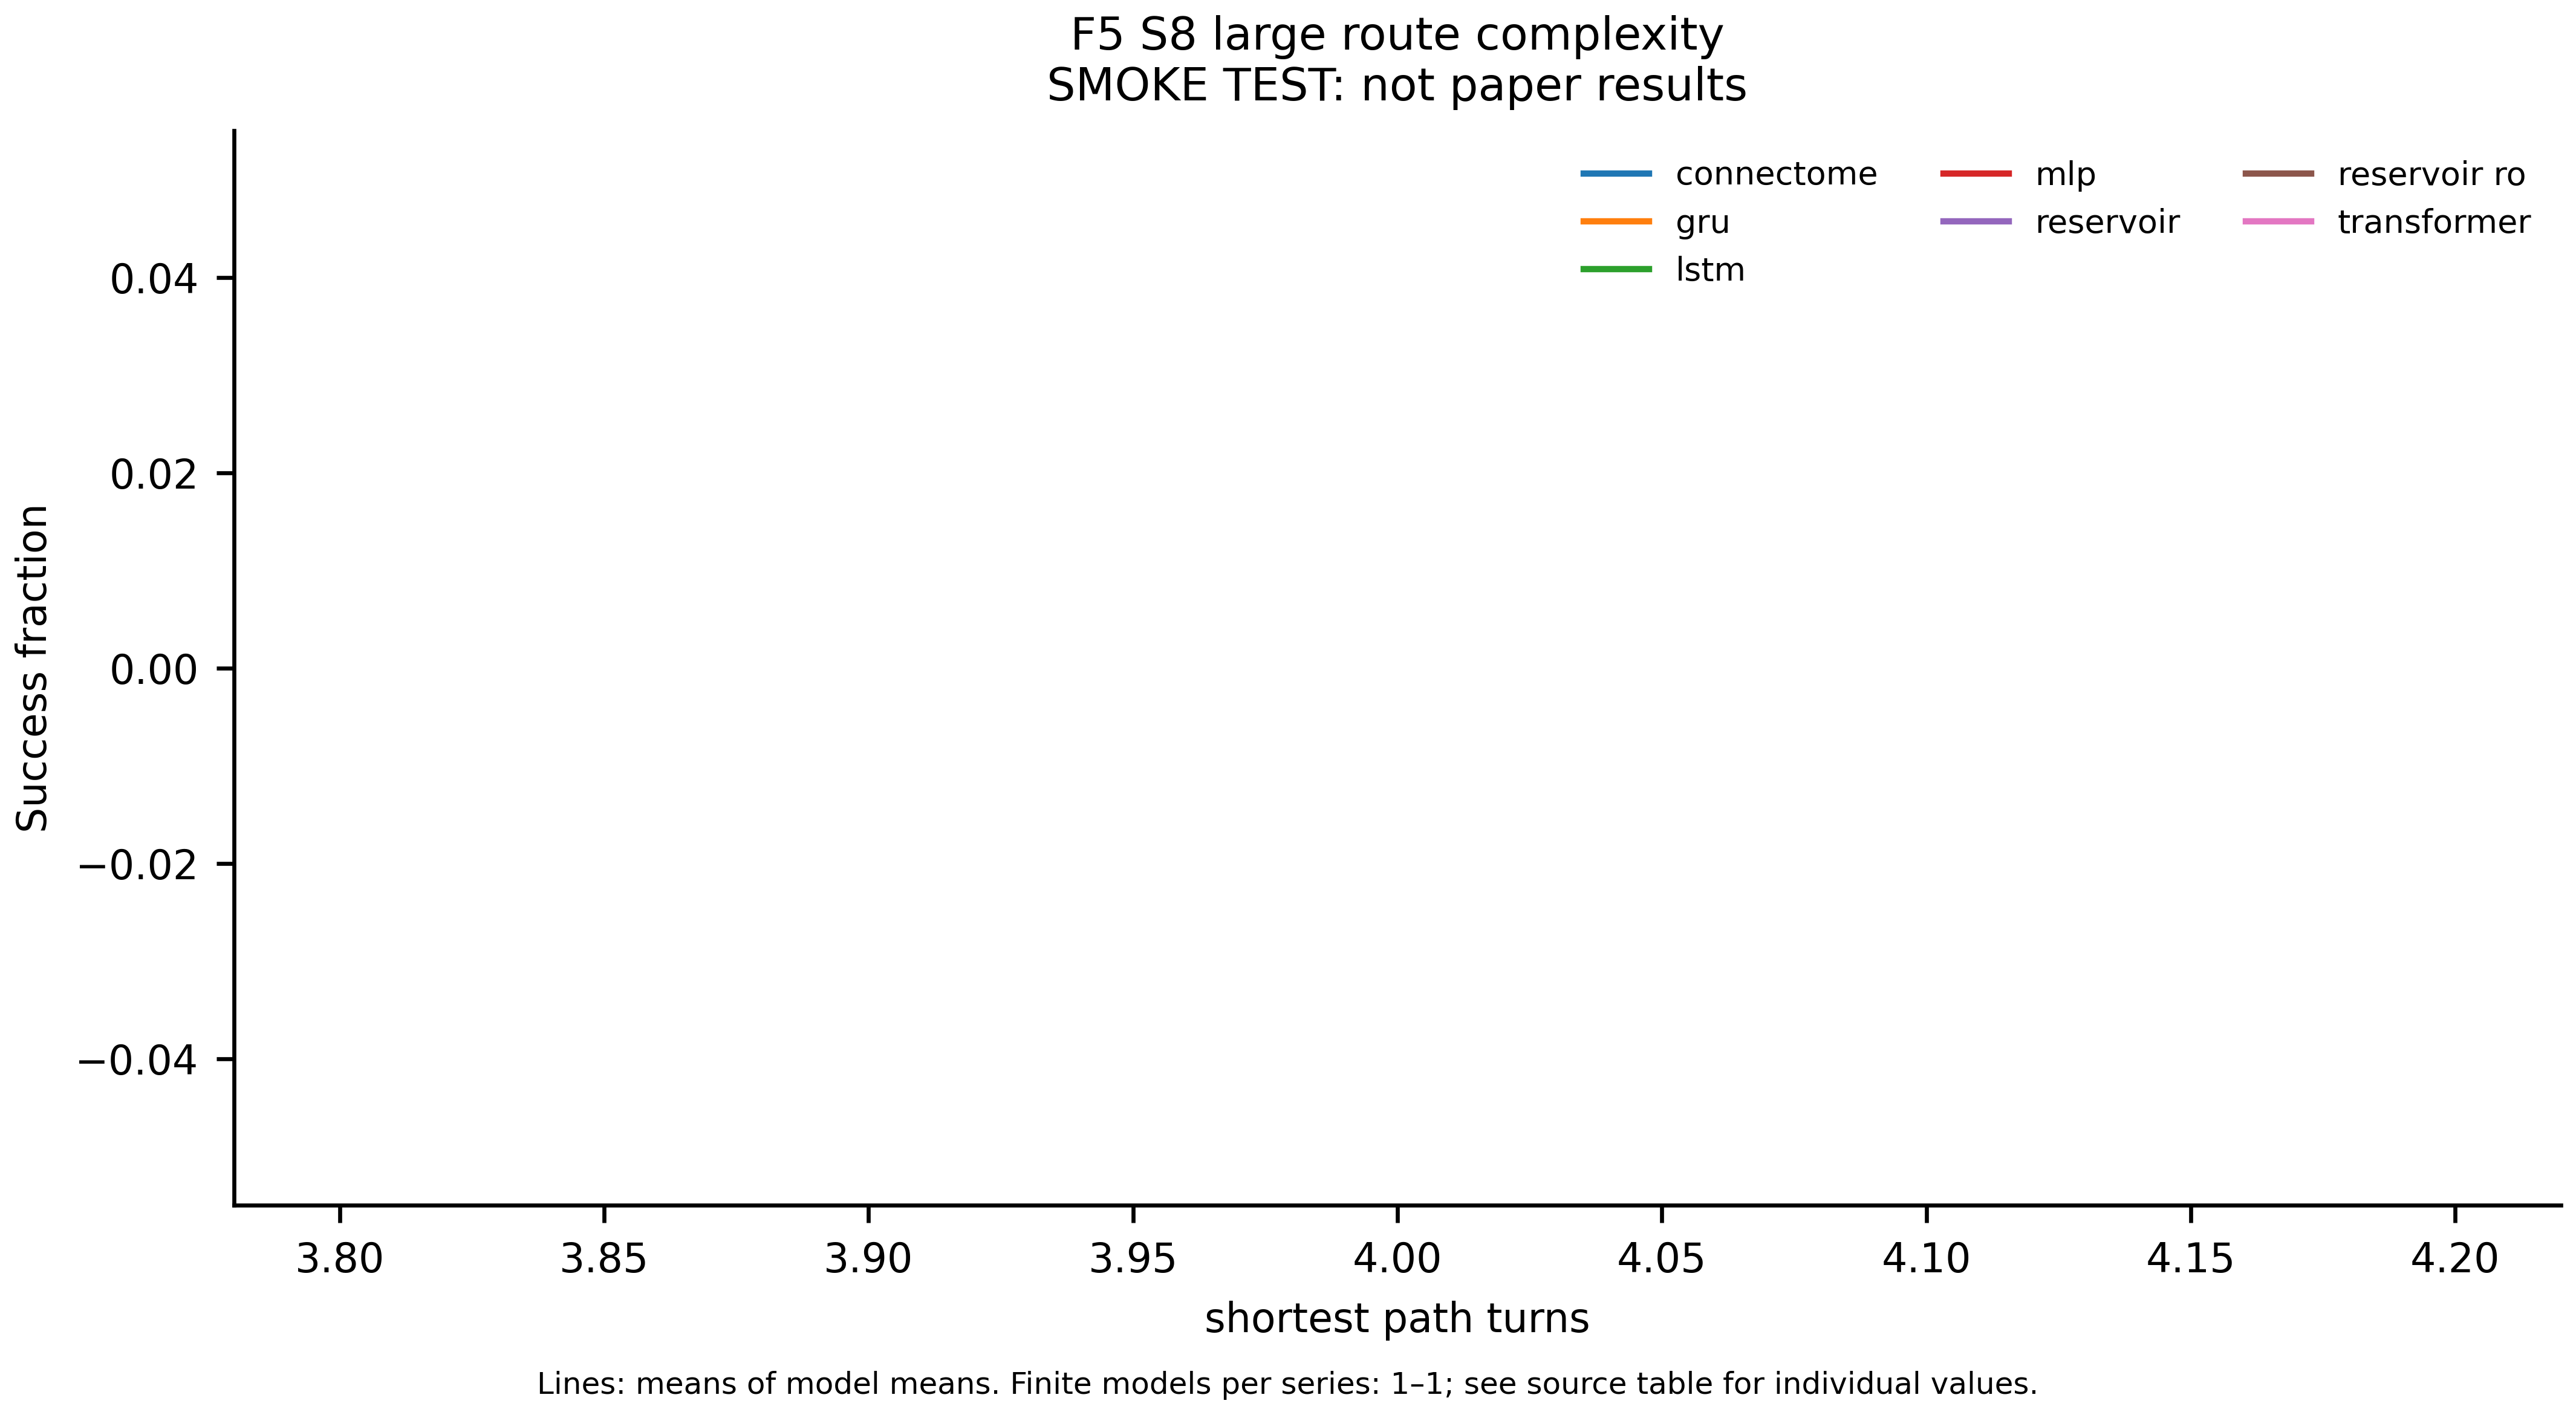

`figures/paper/F5_S8_medium_route_complexity.png`

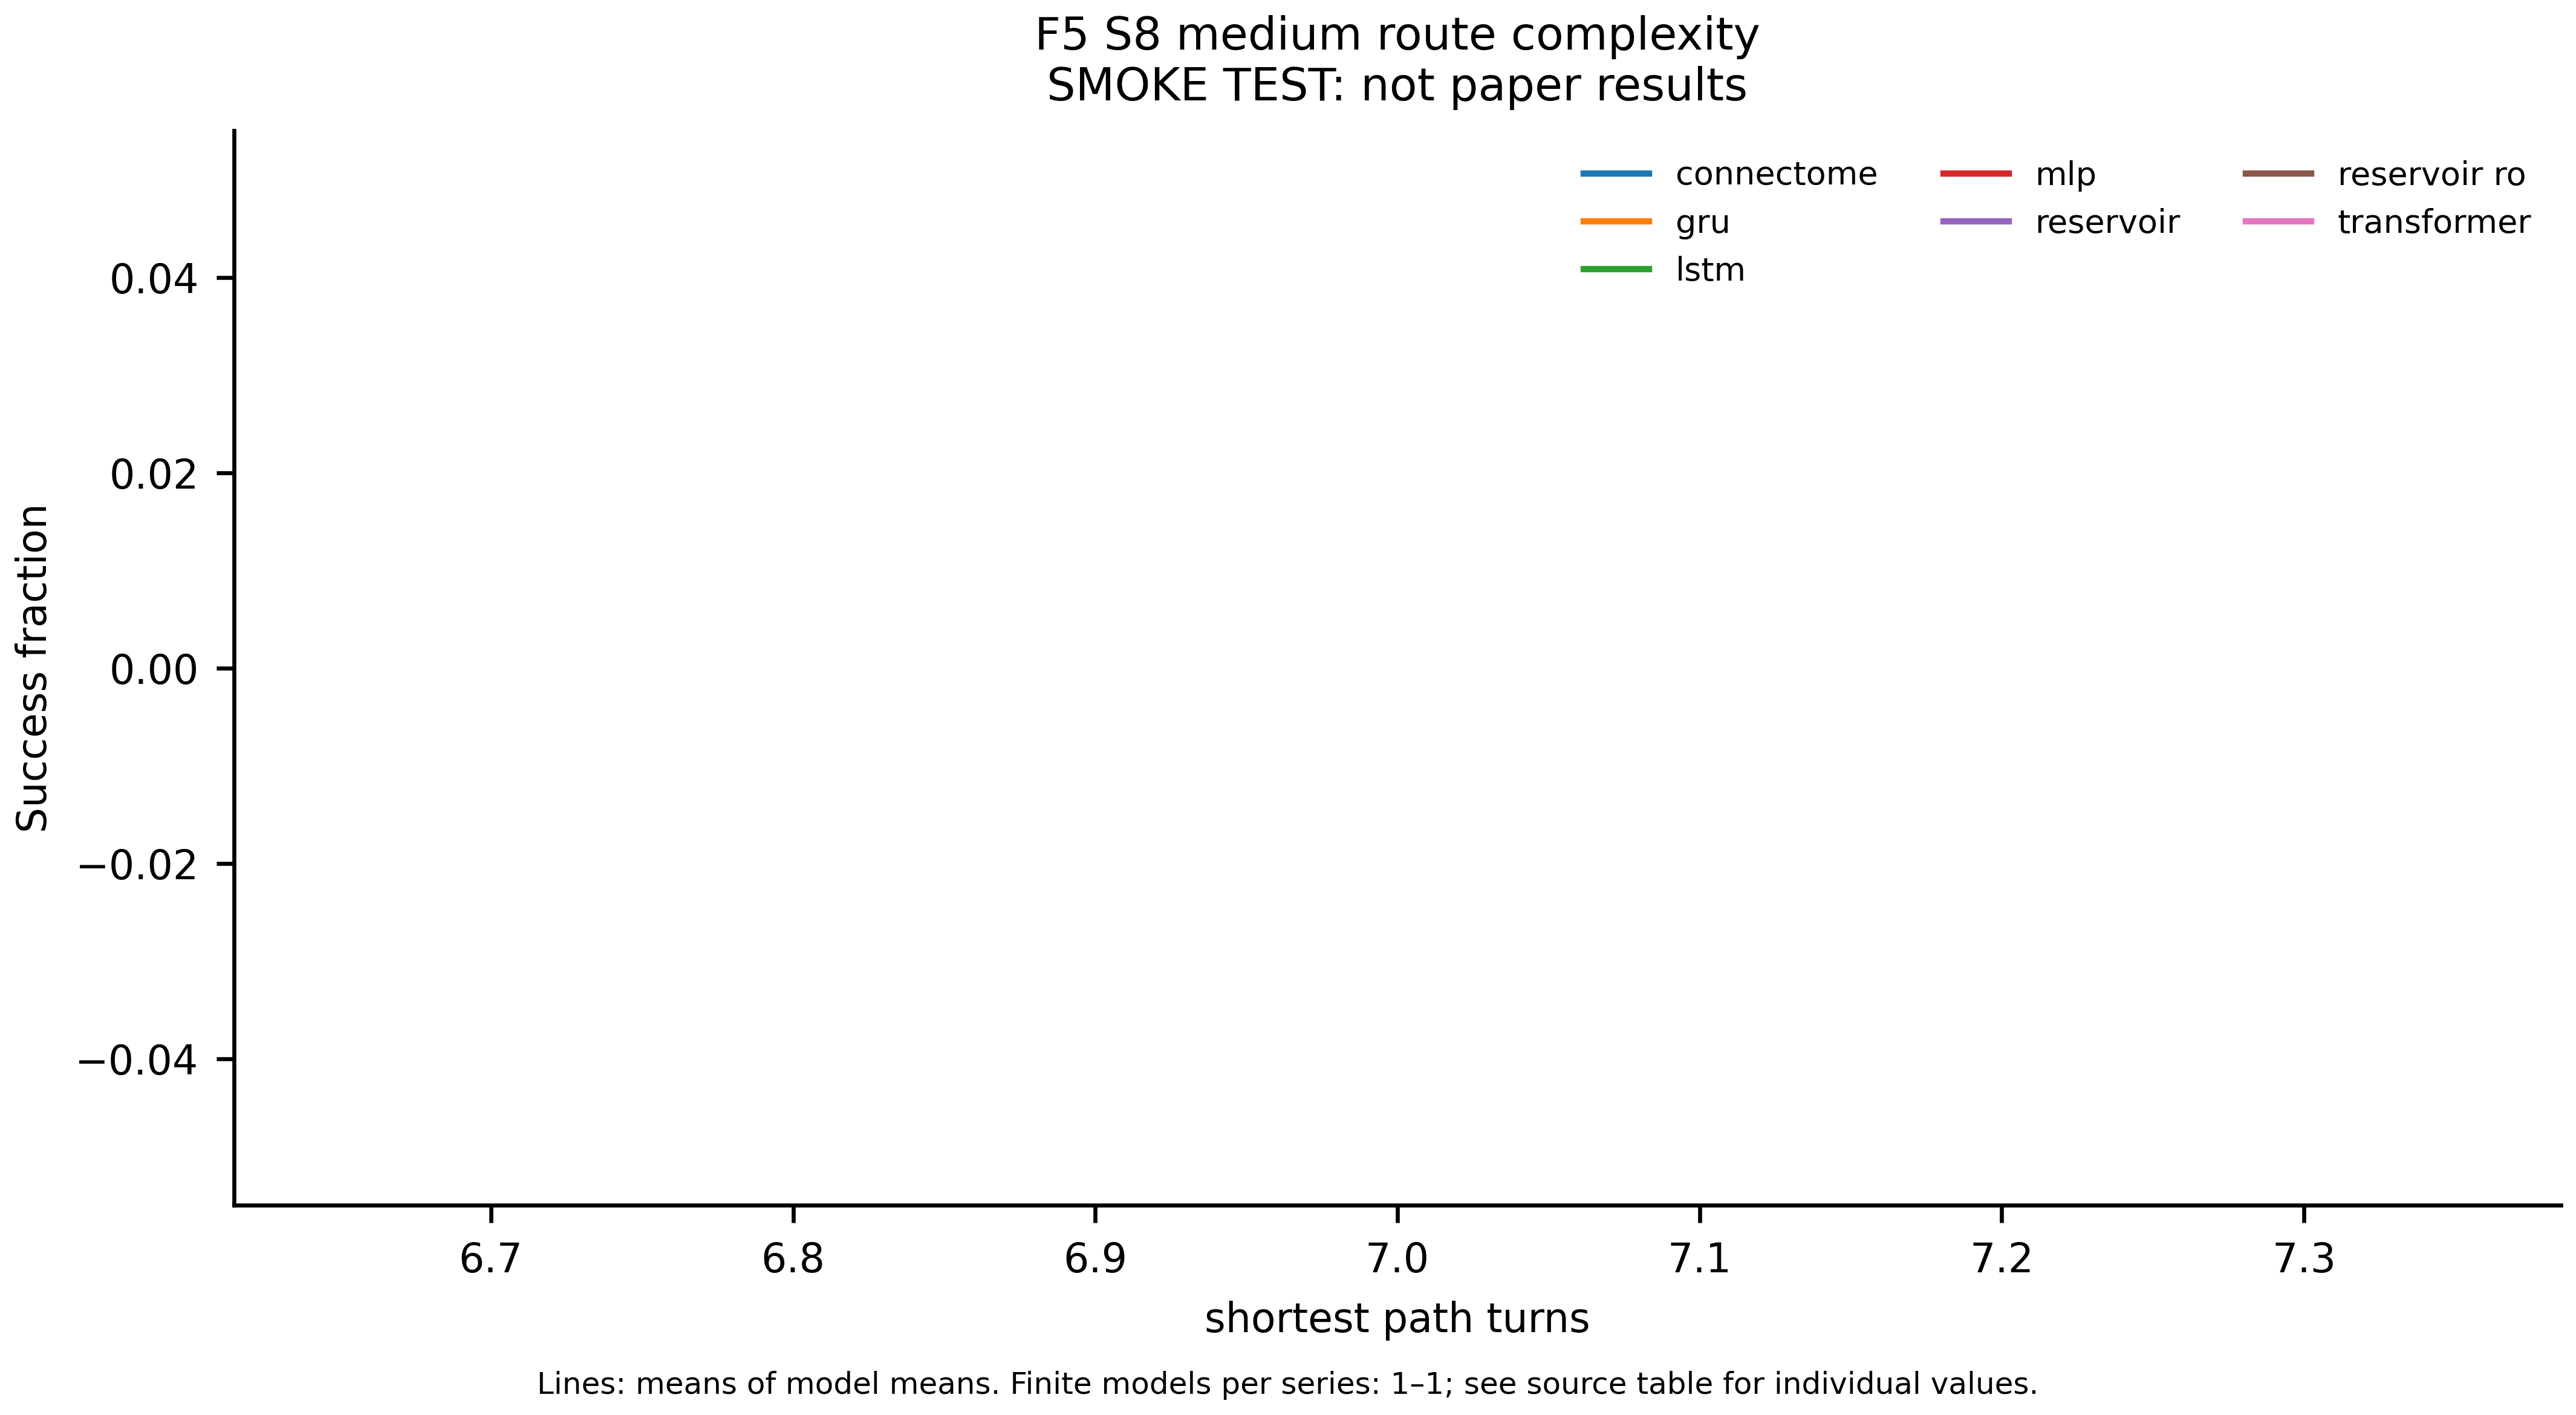

`figures/paper/F5_S8_umaze_route_complexity.png`

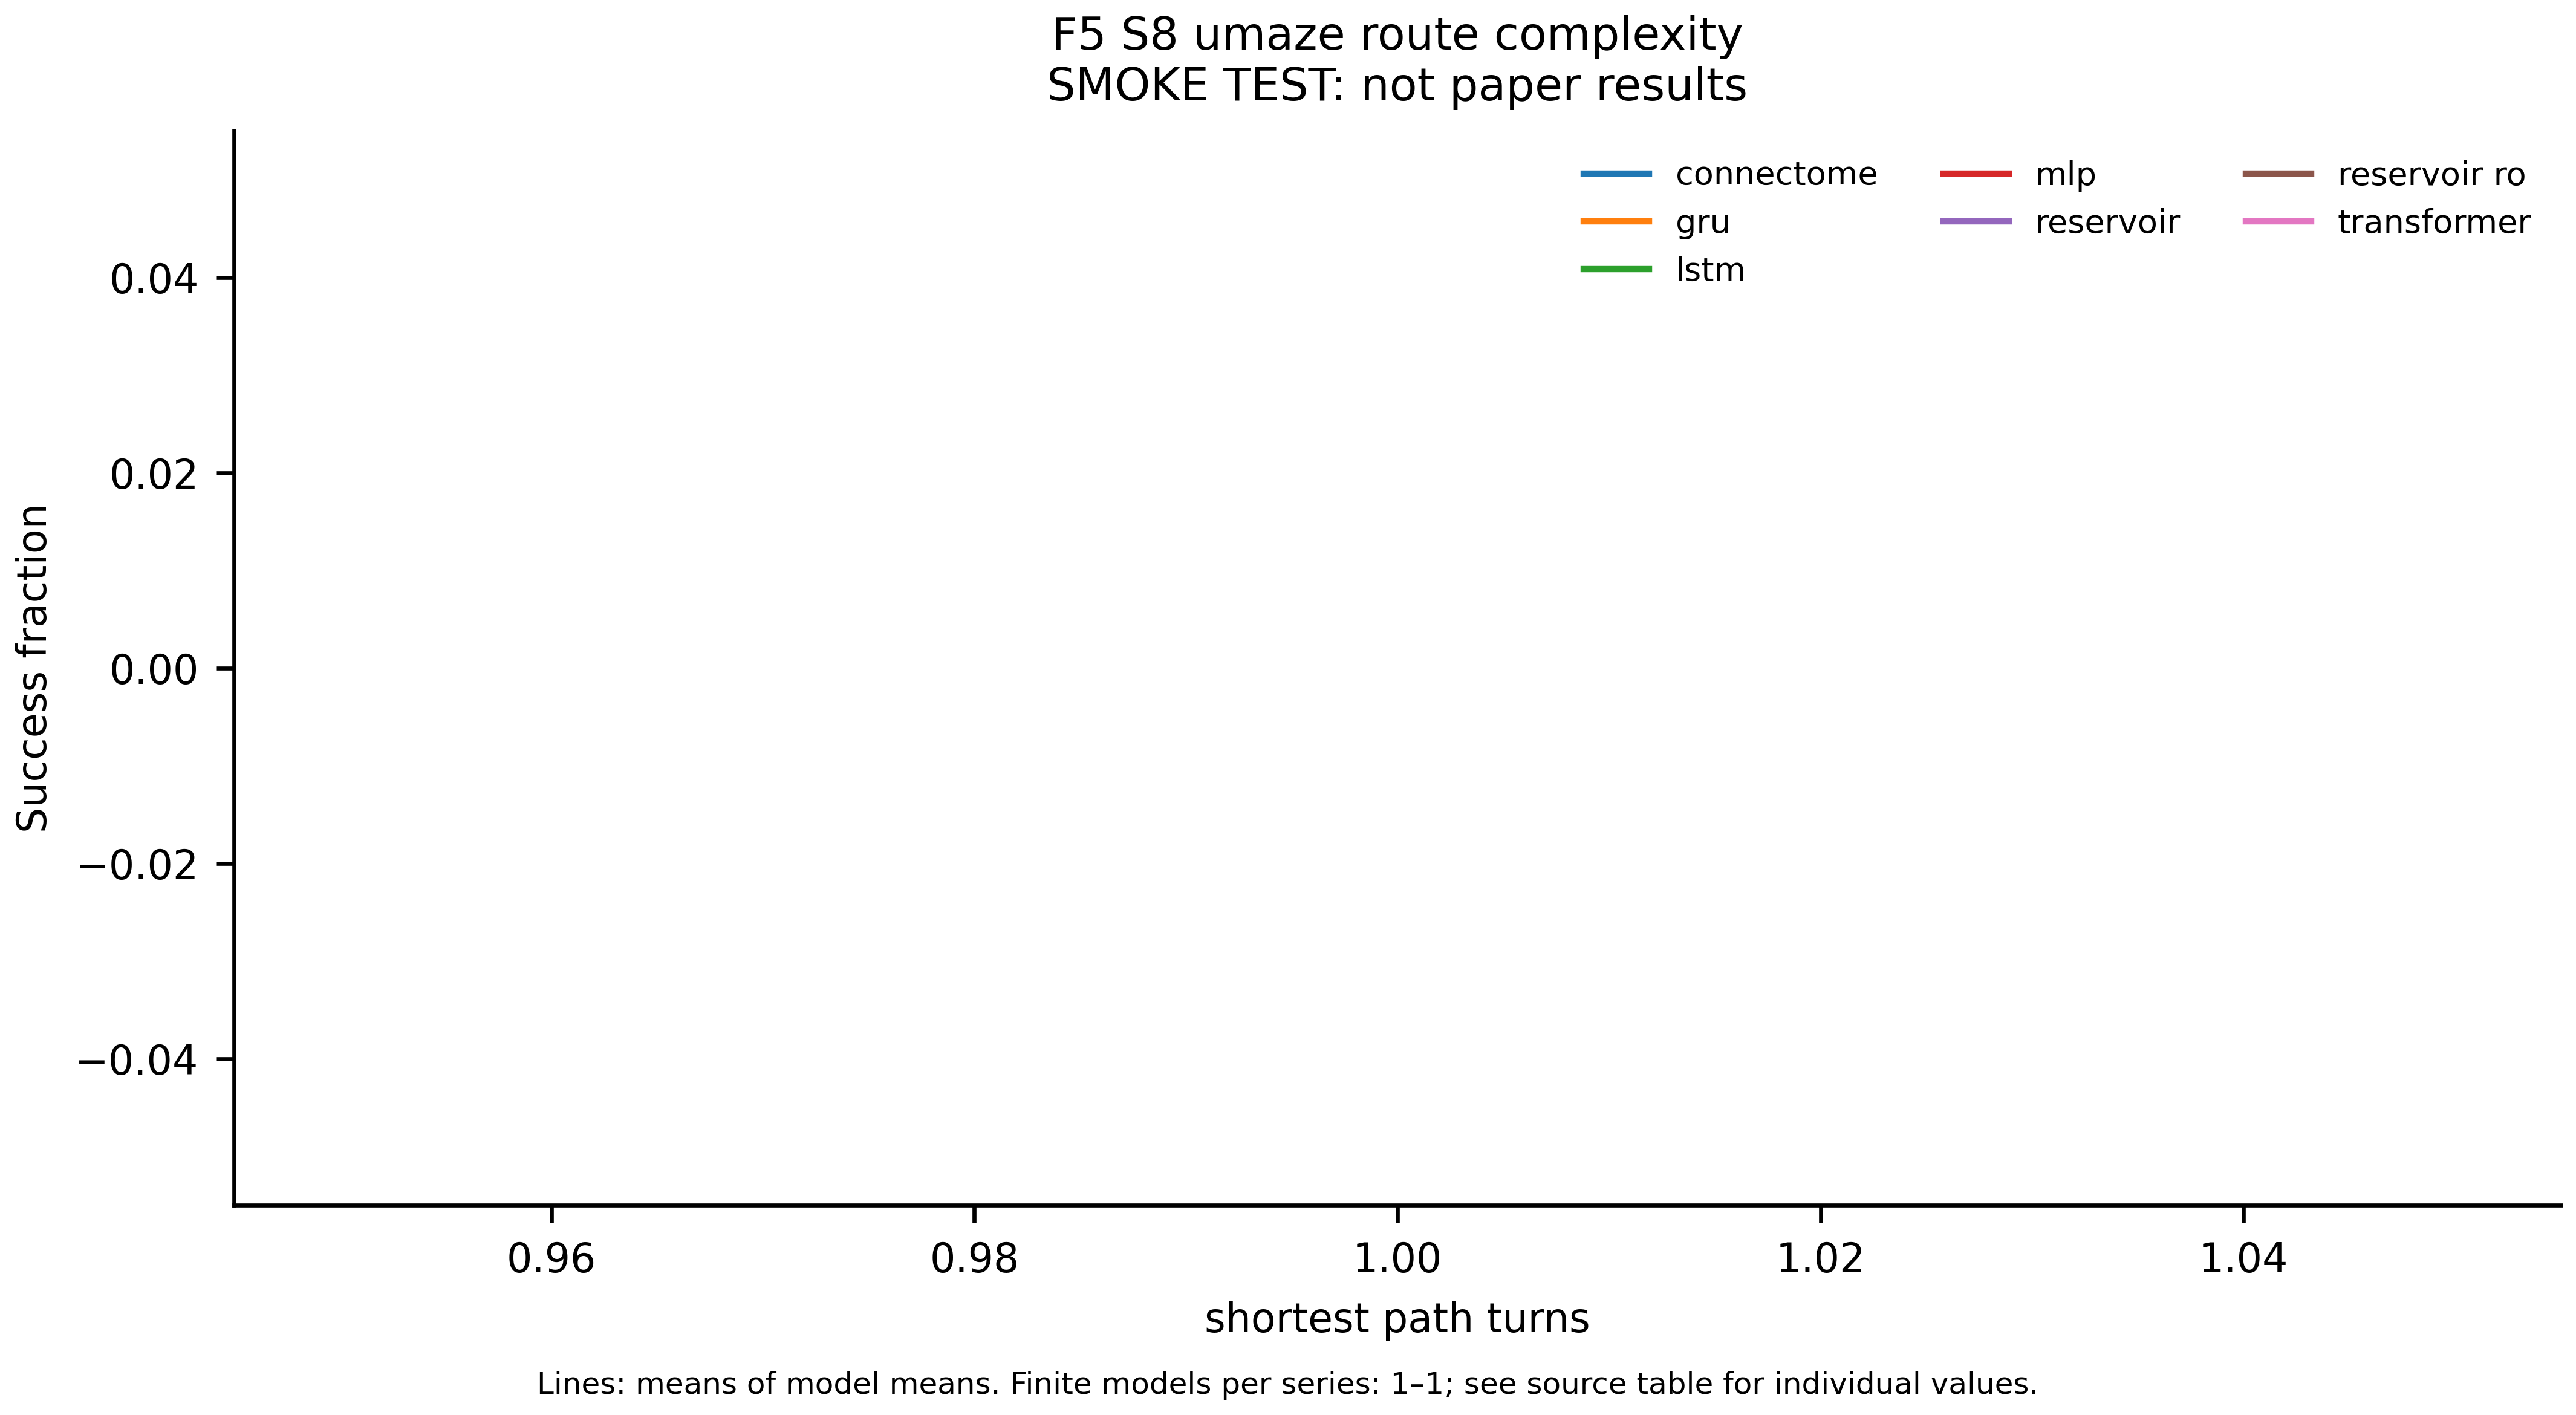

The complete numerical files and figures are saved in `RUN_DIR`. The tables and images displayed here are embedded in this notebook.

In [8]:
show_outputs(RUN_DIR)

## Full reproduction

Run this command in a terminal from the repository root, with the environment activated:

```bash
python scripts/05_maze.py --run-dir runs/maze --device cuda:0 --workers 4
```

Equivalent command:

```bash
flycontrol run --config maze --run-dir runs/maze --device cuda:0 --workers 4
```

Use an available CUDA device, or `cpu`. Without `--smoke`, the script uses the complete fixed seed cohort, training budgets and condition grids. Keep full outputs in a separate run directory. These commands are documentation only; **Run All never launches the full campaign**.
